# 交付时效与准时率分析

物流履约水平：送达时长分布、实际 vs 承诺的准时率、准时率的月度变化。

送达天数 均值 12.1 天（中位 10 天）
平均比承诺提前 11.9 天送达 | 准时率 93.2% | 迟到订单平均迟到 10.6 天


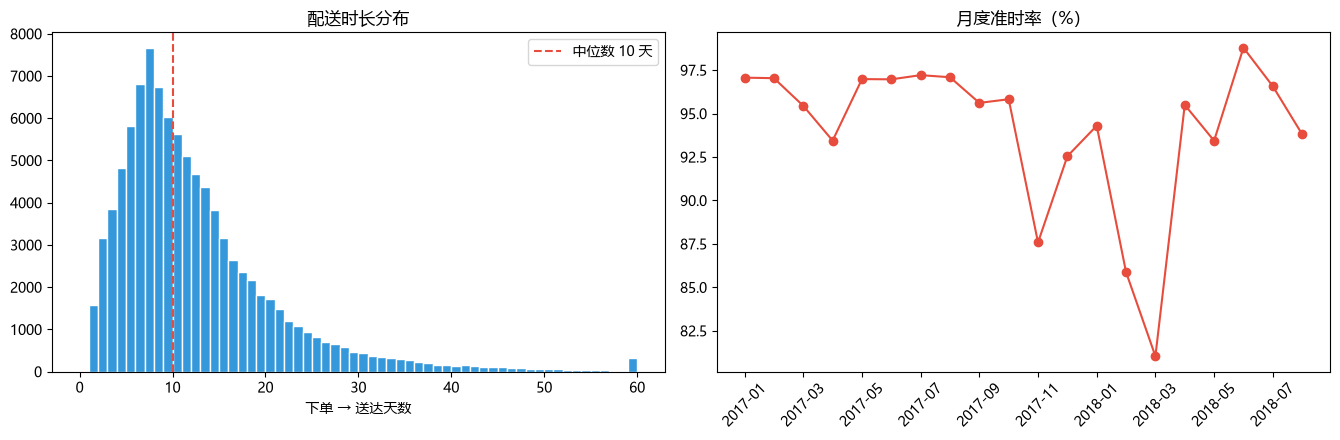

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

orders = pd.read_csv('data/orders_clean.csv', parse_dates=[
    'order_purchase_timestamp', 'order_estimated_delivery_date', 'order_delivered_customer_date'])
o = orders[orders['order_status'] == 'delivered'].drop_duplicates('order_id')
o['dl_days'] = (o['order_delivered_customer_date'] - o['order_purchase_timestamp']).dt.days
o['delay'] = (o['order_delivered_customer_date'] - o['order_estimated_delivery_date']).dt.days
o['ym'] = o['order_purchase_timestamp'].dt.to_period('M')

print('送达天数 均值 %.1f 天（中位 %.0f 天）' % (o['dl_days'].mean(), o['dl_days'].median()))
print('平均比承诺提前 %.1f 天送达 | 准时率 %.1f%% | 迟到订单平均迟到 %.1f 天'
      % (-o['delay'].mean(), (o['delay'] <= 0).mean() * 100, o.loc[o['delay'] > 0, 'delay'].mean()))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))
axes[0].hist(o['dl_days'].clip(upper=60), bins=60, color='#3498db', edgecolor='white')
axes[0].axvline(o['dl_days'].median(), color='#e74c3c', ls='--',
                label=f"中位数 {o['dl_days'].median():.0f} 天")
axes[0].set_xlabel('下单 → 送达天数'); axes[0].set_title('配送时长分布'); axes[0].legend()

ot = o[o['ym'] >= '2017-01'].groupby('ym').apply(lambda g: (g['delay'] <= 0).mean() * 100)
labels = [str(i) for i in ot.index]
axes[1].plot(labels, ot.values, color='#e74c3c', marker='o')
axes[1].set_xticks(labels[::2]); axes[1].tick_params(axis='x', rotation=45)
axes[1].set_title('月度准时率（%）')
plt.tight_layout(); plt.show()


## 结论

- **履约不慢**：平均送达 12.1 天（中位 10 天）；平台预计送达日期整体保守，实际平均比承诺提前 11.9 天送达。
- **准时率 93.2%**：迟到的 6.8% 订单平均迟到 10.6 天，迟到即严重迟到，是差评的主要来源（见评分归因）。
- **服务质量小幅下滑**：准时率从 2017 年的 95.2% 降至 2018 年的 92.4%，与订单量翻倍同步——规模扩张带来了履约压力。

## 业务解读

- 平均 12.1 天送达在巴西并不意外（国土面积大 + 卖家集中东南部 + 国际物流参与），但对比中国电商（2–3 天）说明体验标准差异巨大，评价体系要按本地基准。
- **预计日期过度保守**（实际平均提前 11.9 天送达）：准时率 93.2% 是被「低承诺」撑起来的。把预计日期收窄 5–7 天，既能提升下单转化（等待预期更短），又不至于破坏准时率。
- 准时率 95.2% → 92.4% 的下滑与订单量翻倍同步，是**产能瓶颈的领先指标**；若单量继续增长而物流产能不变，准时率会加速下滑。
- 迟到即严重迟到（平均 10.6 天）：没有「轻微迟到」缓冲带，说明履约链路中存在集中爆点（清关、干线运输），值得做环节拆解。

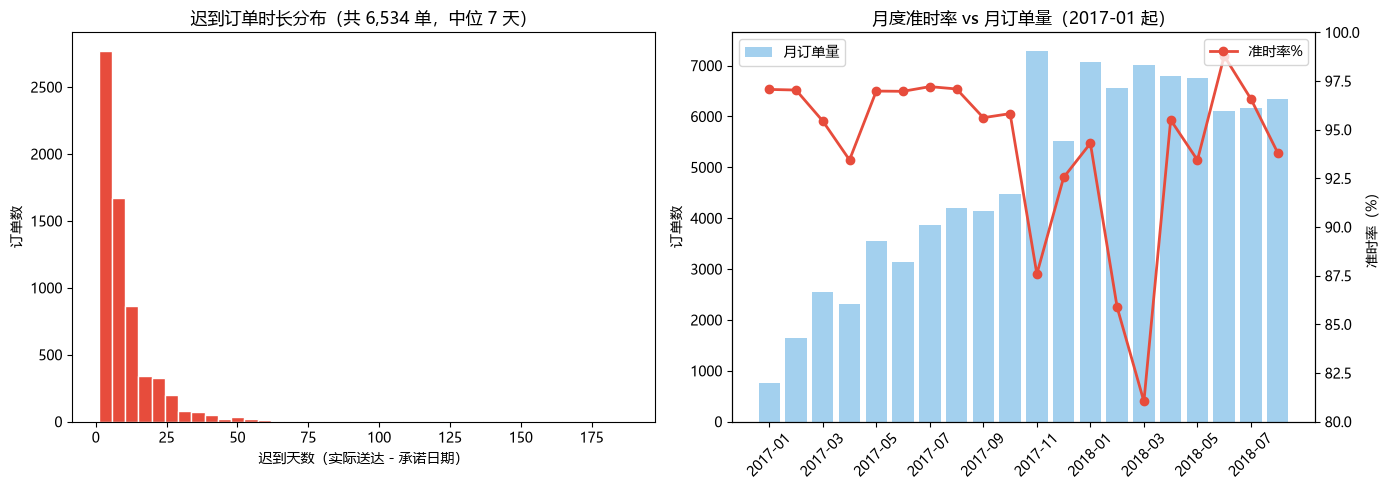

In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ① 迟到时长分布直方图
late_days = o.loc[o['delay'] > 0, 'delay']
axes[0].hist(late_days, bins=40, color='#e74c3c', edgecolor='white')
axes[0].set_xlabel('迟到天数（实际送达 - 承诺日期）'); axes[0].set_ylabel('订单数')
axes[0].set_title(f'迟到订单时长分布（共 {len(late_days):,} 单，中位 {late_days.median():.0f} 天）')

# ② 准时率（折线，左轴）vs 月订单量（柱，右轴）
cnt_m = o[o['ym'] >= '2017-01'].groupby('ym').size()
labels = [str(pp) for pp in cnt_m.index]
xs = list(range(len(labels)))
axes[1].bar(xs, cnt_m.values, color='#3498db', alpha=.45, label='月订单量')
ax2 = axes[1].twinx()
ax2.plot(xs, ot.reindex(cnt_m.index).values, color='#e74c3c', marker='o', lw=2, label='准时率%')
axes[1].set_xticks(xs[::2], labels[::2], rotation=45)
axes[1].set_ylabel('订单数'); ax2.set_ylabel('准时率（%）')
ax2.set_ylim(80, 100)
axes[1].set_title('月度准时率 vs 月订单量（2017-01 起）')
axes[1].legend(loc='upper left'); ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()